# 연습문제 2-5 ~ 2-6 풀이: OR와 NAND 게이트, 입력이 셋인 퍼셉트론

2-2절 연습문제 2-5 ~ 2-6의 풀이 예시다. 정답이 하나뿐인 문제가 아니므로 다른 방법으로도 구현할 수 있다.

- 본문 예제 코드는 `code_examples/ch02/` 아래 예제 노트북을 참고한다.

In [1]:
# 공통 라이브러리와 torch 라이브러리 임포트
import sys
sys.path.append('../../')                   # 공통 라이브러리가 있는 저장소 최상위 폴더

import torch
from code_reference import common
from code_reference import visualize as viz

viz.configure(save_grayscale=False)         # 시각화 결과를 파일에 저장하지 않음
common.set_korean_plot_env()                # matplotlib에서 한글 폰트 사용

## 사전 준비

2-2절의 모델 함수, 손실 함수, 최적화 함수, 학습 루프를 가져온다.
입력 개수가 달라져도 쓸 수 있도록 입력 `X`와 정답 `Y_true`를 인자로 받는다.
학습 로그는 출력 길이를 줄이기 위해 마지막 손실만 돌려주는 조용한 학습 함수를 따로 구현해 사용한다.
모델의 성공 여부 기준은 모든 샘플을 제대로 분류할 수 있는지로 판단한다.

In [2]:
LR = 0.1          # 학습률
EPOCHS = 1000     # 전체 학습 에포크
SEED = 2          # 파라미터 초깃값을 재현할 수 있도록 시드를 고정

def model(X, weights, bias):
    return 1 / (1 + torch.exp(-(X @ weights + bias)))         # 가중합과 시그모이드

def criterion(Y_pred, Y_true):
    return ((Y_pred - Y_true) ** 2).mean()                    # 평균제곱오차

def optimizer(weights, bias, learning_rate):
    with torch.no_grad():
        weights -= learning_rate * weights.grad
        bias -= learning_rate * bias.grad

In [3]:
def train_quiet(X, Y_true, weights, bias, epochs, lr):
    """[코드 2-5]와 같은 학습 루프. 로그 대신 마지막 손실만 반환한다."""
    for _ in range(epochs):
        loss = criterion(model(X, weights, bias), Y_true)
        loss.backward()
        optimizer(weights, bias, lr)
        weights.grad.zero_()
        bias.grad.zero_()
    return loss.item()

In [4]:
def fit(X, Y_true, epochs=EPOCHS, lr=LR, seed=SEED):
    """같은 시드로 초깃값을 만들어 학습하고 (손실, 성공 여부, 가중치, 편향)을 돌려준다."""
    torch.manual_seed(seed)
    weights = torch.randn((X.shape[1], 1), requires_grad=True)    # (입력 개수, 1)
    bias = torch.randn((1,), requires_grad=True)
    loss = train_quiet(X, Y_true, weights, bias, epochs, lr)
    with torch.no_grad():
        ok = torch.equal((model(X, weights, bias) >= 0.5).float(), Y_true)
    return loss, ok, weights, bias

## 연습문제 2-5

> OR 게이트와 NAND 게이트를 시뮬레이션하는 모델을 각각 만들어 보자.
> OR 게이트는 두 개의 입력이 모두 0일 때만 출력이 0이 되고,
> NAND 게이트는 두 입력이 모두 1일 때만 출력이 0이 된다.

> OR 게이트와 NAND 게이트의 진리표(입력값과 출력값)
> | x1 | x2 | OR 게이트 출력 | NAND 게이트 출력 |
> |---|---|---|---|
> | 0 | 0 | 0 | 1 |
> | 0 | 1 | 1 | 1 |
> | 1 | 0 | 1 | 1 |
> | 1 | 1 | 1 | 0 |

**OR 게이트와 NAND 게이트의 정답 텐서 만들기**
- 입력 `X`와 모델, 학습 루프는 AND 게이트 예제와 같고 정답 텐서 `Y_true`만 게이트마다 달라진다
- OR: 두 입력이 모두 0일 때만 0, NAND: 두 입력이 모두 1일 때만 0
- 비교를 위해 본문 예제의 AND 게이트도 함께 만든다

In [5]:
X = torch.tensor([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])    # (4, 2): 입력
GATES = {
    'AND': torch.tensor([[0.], [0.], [0.], [1.]]),     # 비교용: 본문의 AND 게이트
    'OR': torch.tensor([[0.], [1.], [1.], [1.]]),      # 둘 다 0일 때만 0
    'NAND': torch.tensor([[1.], [1.], [1.], [0.]]),    # 둘 다 1일 때만 0
}
for name, Y_true in GATES.items():
    print(f'{name:>4} 정답: {Y_true.flatten().int().tolist()}')

 AND 정답: [0, 0, 0, 1]
  OR 정답: [0, 1, 1, 1]
NAND 정답: [1, 1, 1, 0]


**세 게이트 학습하고 결정 경계 비교하기**
- 같은 시드로 초깃값을 만들어 게이트마다 학습
- 결정 경계의 기울기는 -w1 / w2, x2축 절편은 -b / w2

In [6]:
fits = {}                                   # 게이트별 (w1, w2, b)
for name, Y_true in GATES.items():
    loss, ok, weights, bias = fit(X, Y_true)
    w1, w2, b = weights[0].item(), weights[1].item(), bias.item()
    fits[name] = (w1, w2, b)
    print(f'{name:>4}: 손실 {loss:.4f}, 분류 성공 {ok}')
    print(f'      가중치 ({w1:5.2f}, {w2:5.2f}), 편향 {b:5.2f}, '
          f'기울기 {-w1 / w2:5.2f}, 절편 {-b / w2:5.2f}')

 AND: 손실 0.0576, 분류 성공 True
      가중치 ( 1.86,  1.85), 편향 -2.94, 기울기 -1.01, 절편  1.59
  OR: 손실 0.0360, 분류 성공 True
      가중치 ( 2.50,  2.44), 편향 -0.87, 기울기 -1.02, 절편  0.36
NAND: 손실 0.0611, 분류 성공 True
      가중치 (-1.76, -1.78), 편향  2.82, 기울기 -0.99, 절편  1.58


**세 결정 경계 시각화하기**
- 공통 라이브러리의 `plot_decision_boundary()`로 게이트마다 그림을 한 장씩 그림
- 정답이 1인 입력은 채운 원, 0인 입력은 빈 원
- 직선은 학습한 가중치와 편향 `(w1, w2, b)`로 그림

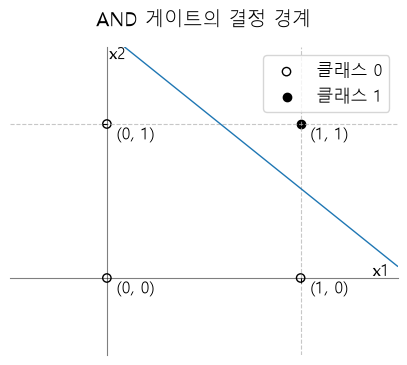

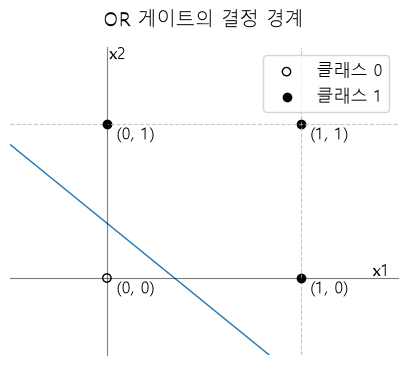

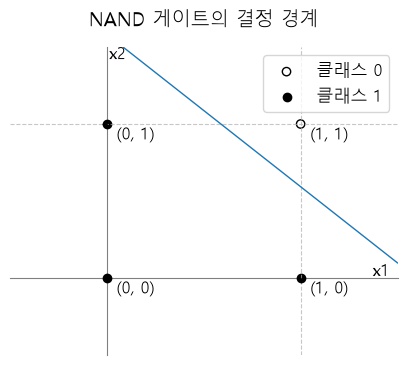

In [7]:
x1_list = X[:, 0].int().tolist()            # 네 입력의 x1, x2 좌표
x2_list = X[:, 1].int().tolist()
for name, Y_true in GATES.items():
    y_list = Y_true.flatten().int().tolist()                        # 정답 목록
    sample = (x1_list, x2_list, y_list)
    viz.plot_decision_boundary(
        sample, params=[fits[name]], title=f'{name} 게이트의 결정 경계',
        x_label='x1', y_label='x2', figsize=(5, 4),
    )

**결과 분석: 정답만 바꿔도 세 게이트가 모두 학습된다**
- 모델과 학습 루프는 그대로이고 정답 텐서만 바꿨는데 OR, NAND도 모든 샘플을 정답으로 분류
- 세 게이트의 결정 경계 기울기는 모두 약 -1: 직선의 방향은 같고 위치(절편)만 다름
- OR는 절편이 작아 경계가 원점 쪽으로 당겨지고, NAND는 AND와 가중치와 편향의 부호가 반대
- 그림에서 AND와 NAND의 직선은 거의 같은 위치: 둘 다 (1, 1)을 나머지 세 점에서 갈라내고, 1로 분류하는 쪽만 반대
- OR의 직선은 (0, 0)을 나머지 세 점에서 갈라냄

## 연습문제 2-6

> 입력이 세 개인 AND 게이트를 시뮬레이션하는 모델을 만들어 보자.
> 이 게이트는 세 입력이 모두 1일 때만 1을 출력한다.
>
> 힌트: 2-2절의 예제와 다른 하이퍼파라미터의 값을 사용해야 할 수도 있다.

**본문 설정으로 입력 세 개 AND 게이트 학습하기**
- 입력이 세 개이므로 샘플은 2^3 = 8개, 가중치는 (3, 1) 형태
- 학습률 0.1, 1,000 에포크는 2-2절과 같게 둔다
- 입력이 세 개인 AND 게이트의 진리표(입력값과 출력값)

  |x1|x2|x3|AND 게이트 출력|비고|
  |---|---|---|---|---|
  | 0 | 0 | 0 | 0 ||
  | 0 | 0 | 1 | 0 ||
  | 0 | 1 | 0 | 0 ||
  | 0 | 1 | 1 | 0 ||
  | 1 | 0 | 0 | 0 ||
  | 1 | 0 | 1 | 0 ||
  | 1 | 1 | 0 | 0 ||
  | 1 | 1 | 1 | 1 |입력이 모두 1일 때만 1|


In [8]:
# 입력 세 개의 모든 조합 8개: 0부터 7까지를 이진수로 바꾼 것
X = torch.tensor([[float(bit) for bit in f'{i:03b}'] for i in range(8)])    # (8, 3)
Y = torch.zeros((8, 1))
Y[7] = 1.                                  # (1, 1, 1)일 때만 1

loss, ok, weights, bias = fit(X, Y)
w = weights.flatten().tolist()
print(f'학습률 {LR}, 에포크 {EPOCHS:,}: 손실 {loss:.4f}, 분류 성공 {ok}')
print(f'가중치 ({w[0]:.2f}, {w[1]:.2f}, {w[2]:.2f}), 편향 {bias.item():.2f}')
with torch.no_grad():
    z = (torch.tensor([[1., 1., 1.]]) @ weights + bias).item()
print(f'(1, 1, 1)의 가중합 z: {z:.3f}')

학습률 0.1, 에포크 1,000: 손실 0.0692, 분류 성공 False
가중치 (0.91, 0.83, 0.82), 편향 -2.79
(1, 1, 1)의 가중합 z: -0.221


**결과 분석: 손실은 작아도 분류에 실패한다**
- 손실이 작게 나와도 (1, 1, 1)의 가중합 z가 음수라서 그 샘플을 틀림
- 2-2절의 최종 손실 0.0576과 비슷해 보여서, 분류 결과를 따로 확인하지 않으면 성공으로 착각하기 쉬움

**하이퍼파라미터 바꿔 보기**
- 힌트대로 에포크를 늘리거나 학습률을 키워 같은 시드로 다시 학습

In [9]:
print('학습률   에포크     손실   분류 성공')
for lr, epochs in ((0.1, 1000), (0.1, 2000), (0.3, 1000), (0.3, 2000)):
    loss, ok, _, _ = fit(X, Y, epochs, lr)
    print(f'{lr:6.1f}   {epochs:6,d}   {loss:6.4f}   {str(ok):>9}')

학습률   에포크     손실   분류 성공
   0.1    1,000   0.0692       False
   0.1    2,000   0.0485        True
   0.3    1,000   0.0375        True
   0.3    2,000   0.0219        True


**결과 확인: 에포크를 늘리거나 학습률을 키우면 성공한다**
- 학습률 0.1, 1,000 에포크만 실패하고, 에포크를 2,000으로 늘리거나 학습률을 0.3으로 키우면 성공
- 입력이 늘어도 정답이 1인 샘플은 하나뿐: 샘플 4개 중 1개에서 8개 중 1개가 되어 학습이 더뎌짐
- 입력이 셋이면 결정 경계는 직선이 아니라 평면: x1 * w1 + x2 * w2 + x3 * w3 + b = 0

**직접 해 보기: 시드를 바꿔 10번씩 학습하면?**
- 초깃값을 정하는 시드를 1부터 10까지 바꿔, 설정마다 입력 세 개 AND 게이트를 10번씩 학습
- 본문 설정(학습률 0.1, 1,000 에포크)은 시드를 바꾸면 성공할까? 어떤 설정이 가장 좋은 설정일까?

In [10]:
print('학습률   에포크    시드 1~10 중 분류에 성공한 횟수')
for lr, epochs in ((0.1, 1000), (0.1, 2000), (0.3, 1000), (0.3, 2000)):
    success = sum(fit(X, Y, epochs, lr, seed)[1] for seed in range(1, 11))
    print(f'{lr:6.1f}   {epochs:6,d}    {success:2d}번')

학습률   에포크    시드 1~10 중 분류에 성공한 횟수
   0.1    1,000     0번
   0.1    2,000     5번
   0.3    1,000     9번
   0.3    2,000    10번


**확인**
- 본문 예제의 설정(학습률 0.1, 1,000 에포크)은 시드 10개 모두 실패: 시드가 아니라 설정이 문제
- 에포크를 2,000으로 늘리면 10번 중 5번, 학습률을 0.3으로 키우면 9번, 둘 다 바꾸면 10번 모두 성공
- 하이퍼파라미터는 모델과 데이터에 맞춰 정해야 하며, 손실만 보지 말고 분류 결과를 함께 확인